# Data overview

What the development and external test data look like, read from the combined manifest (`data/manifests/manifest.parquet`, written by `make pipeline`). Counts and charts only; no images are shown.

External test sets are summarised the way they are evaluated: one image per duplicate group (a duplicated eye counts once), groups whose copies disagree on *referable* dropped.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from retinaguard.data.splits import one_image_per_group

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
manifest = pd.read_parquet(ROOT / "data" / "manifests" / "manifest.parquet")
SOURCES = ["eyepacs", "aptos", "idrid", "ddr"]
DEV_SPLITS = ["train", "val", "calib", "test_internal"]
external = manifest[manifest["split"] == "test_external"]
evaluated = pd.concat(
    [manifest[manifest["split"] != "test_external"], one_image_per_group(external)]
)
print(f"{len(manifest):,} images, {len(evaluated):,} after counting duplicated eyes once")

52,977 images, 52,507 after counting duplicated eyes once


## Sources and splits

EyePACS (US) is split by patient; the other sites are only tested on.

In [2]:
table = pd.crosstab(
    [manifest["source"], manifest["site_country"]],
    manifest["split"],
    margins=True,
    margins_name="total",
)
table[[*DEV_SPLITS, "test_external", "total"]]

,split,train,val,calib,test_internal,test_external,total
source,site_country,,,,,,
aptos,IN,0,0,0,0,3662,3662
ddr,CN,0,0,0,0,13673,13673
eyepacs,US,24614,3504,3508,3500,0,35126
idrid,IN,0,0,0,0,516,516
total,,24614,3504,3508,3500,17851,52977


## DR grade per site

ICDR grade shares (%) per EyePACS split and per external site. *Ungradable* is DDR's grade 5 (no DR grade; a quality-gate reject). Referable = grade 2 or above, among graded images.

In [3]:
def grade_rows(frame: pd.DataFrame, name: str) -> dict[str, object]:
    grades = frame["dr_grade"].astype("Int64")
    shares = grades.value_counts(dropna=False, normalize=True).mul(100)
    row: dict[str, object] = {"set": name, "images": len(frame)}
    row.update({str(g): shares.get(g, 0.0) for g in range(5)})
    row["ungradable"] = 100 * grades.isna().mean()
    row["referable %"] = 100 * frame["referable"].dropna().astype(bool).mean()
    return row


sets = [(f"eyepacs {s}", evaluated[evaluated["split"] == s]) for s in DEV_SPLITS]
sets += [(s, evaluated[evaluated["source"] == s]) for s in SOURCES[1:]]
grades = pd.DataFrame([grade_rows(frame, name) for name, frame in sets]).set_index("set")
grades.round(1)

,images,0,1,2,3,4,ungradable,referable %
set,,,,,,,,
eyepacs train,24614,73.6,6.9,15.0,2.5,2.0,0.0,19.5
eyepacs val,3504,73.0,7.2,15.6,2.3,1.9,0.0,19.8
eyepacs calib,3508,73.4,7.1,15.2,2.3,2.1,0.0,19.6
eyepacs test_internal,3500,73.5,7.0,15.1,2.4,2.0,0.0,19.5
aptos,3517,51.1,9.7,26.4,5.0,7.8,0.0,39.2
idrid,508,32.9,4.5,32.5,17.9,12.2,0.0,62.6
ddr,13356,45.8,4.6,32.6,1.7,6.7,8.6,44.8


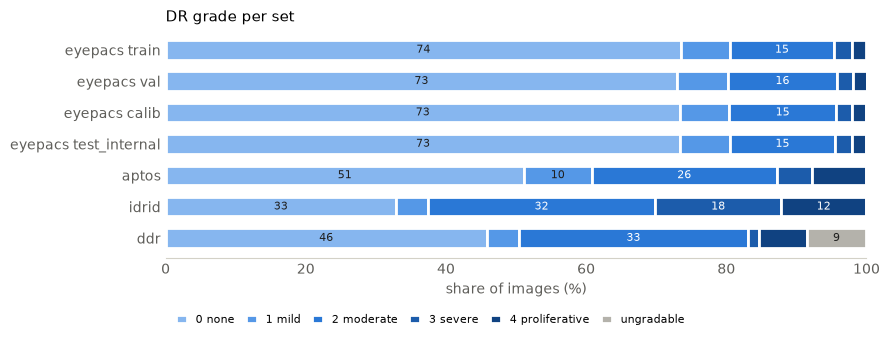

In [4]:
# Ordinal grades on one blue ramp (light = grade 0), ungradable in neutral grey.
COLORS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#b4b2ab"]
LABELS = ["0 none", "1 mild", "2 moderate", "3 severe", "4 proliferative", "ungradable"]
shares = grades[["0", "1", "2", "3", "4", "ungradable"]].iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 3.6))
left = pd.Series(0.0, index=shares.index)
for column, color, label in zip(shares.columns, COLORS, LABELS, strict=True):
    ax.barh(
        shares.index,
        shares[column],
        left=left,
        color=color,
        label=label,
        height=0.62,
        edgecolor="white",
        linewidth=2,
    )
    for y, (x0, width) in enumerate(zip(left, shares[column], strict=True)):
        if width >= 8:
            ink = "#1f1f1e" if column in ("0", "1", "ungradable") else "white"
            ax.text(
                x0 + width / 2, y, f"{width:.0f}", ha="center", va="center", fontsize=8, color=ink
            )
    left += shares[column]
ax.set_xlim(0, 100)
ax.set_xlabel("share of images (%)", color="#5f5e5a")
ax.set_title("DR grade per set", loc="left", fontsize=11)
ax.tick_params(colors="#5f5e5a", length=0)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#d3d1c7")
ax.legend(
    ncols=6,
    loc="upper left",
    bbox_to_anchor=(0, -0.2),
    frameon=False,
    fontsize=8,
    handlelength=1,
    columnspacing=1,
)
fig.tight_layout()
plt.show()

## Image quality

EyePACS quality comes from EyeQ (good / usable / reject) and covers part of the images; DDR marks ungradable images. Shares (%) of labelled images, and label coverage.

In [5]:
eyepacs = manifest[manifest["source"] == "eyepacs"]
quality = pd.crosstab(eyepacs["split"], eyepacs["quality_label"], normalize="index").mul(100)
quality = quality[["good", "usable", "reject"]].loc[DEV_SPLITS]
quality["labelled"] = eyepacs.groupby("split")["quality_label"].count()
quality["coverage %"] = 100 * quality["labelled"] / eyepacs["split"].value_counts()
quality.round(1)

quality_label,good,usable,reject,labelled,coverage %
split,,,,,
train,66.5,15.1,18.4,8833,35.9
val,68.0,13.9,18.2,1217,34.7
calib,66.2,15.3,18.5,1241,35.4
test_internal,65.9,14.3,19.8,1252,35.8


Quality against DR grade (EyePACS, labelled images, % of each grade):

In [6]:
labelled = eyepacs.dropna(subset=["quality_label"])
by_grade = pd.crosstab(labelled["dr_grade"], labelled["quality_label"], normalize="index")
by_grade[["good", "usable", "reject"]].mul(100).round(1)

quality_label,good,usable,reject
dr_grade,,,
0,68.6,14.6,16.7
1,76.7,11.3,12.0
2,60.8,15.6,23.5
3,50.2,23.7,26.1
4,15.5,23.1,61.4


## Image sizes and preprocessing

Raw resolution per site and images the fundus crop could not process (kept in the manifest without a processed file).

In [7]:
sizes = manifest.assign(size=manifest["width"].astype(str) + "x" + manifest["height"].astype(str))
rows = []
for source, frame in sizes.groupby("source"):
    counts = frame["size"].value_counts(normalize=True)
    megapixels = frame["width"].astype(float) * frame["height"].astype(float) / 1e6
    rows.append(
        {
            "source": source,
            "distinct sizes": frame["size"].nunique(),
            "most common": f"{counts.index[0]} ({100 * counts.iloc[0]:.0f}%)",
            "median MP": round(megapixels.median(), 1),
            "min MP": round(megapixels.min(), 2),
            "max MP": round(megapixels.max(), 1),
            "not processed": int(frame["processed_path"].isna().sum()),
        }
    )
pd.DataFrame(rows).set_index("source").loc[SOURCES]

,distinct sizes,most common,median MP,min MP,max MP,not processed
source,,,,,,
eyepacs,29,3888x2592 (29%),10.1,0.13,17.9,4
aptos,17,1050x1050 (27%),3.1,0.17,12.2,0
idrid,1,4288x2848 (100%),12.2,12.21,12.2,0
ddr,132,2592x1728 (17%),4.5,0.50,17.9,1


## Duplicates

Images are grouped by patient, and groups linked by a confirmed near-duplicate are merged. A *duplicate group* joins images of more than one patient (EyePACS) or more than one image (sites without patient ids).

In [8]:
keys = manifest["patient_id"].fillna(manifest["image_id"])
per_group = (
    manifest.assign(key=keys)
    .groupby("split_group")
    .agg(
        source=("source", "first"),
        sources=("source", "nunique"),
        images=("image_id", "size"),
        keys=("key", "nunique"),
        grades=("dr_grade", "nunique"),
        referable=("referable", "nunique"),
    )
)
assert (per_group["sources"] == 1).all(), "a duplicate group spans datasets"
duplicated = per_group[per_group["keys"] > 1]
summary = (
    pd.DataFrame(
        {
            "images": manifest["source"].value_counts(),
            "groups": per_group["source"].value_counts(),
            "duplicate groups": duplicated["source"].value_counts(),
            "images in them": duplicated.groupby("source")["images"].sum(),
            "largest": duplicated.groupby("source")["images"].max(),
            "grade differs": duplicated[duplicated["grades"] > 1]["source"].value_counts(),
            "referable differs": duplicated[duplicated["referable"] > 1]["source"].value_counts(),
            "evaluated": evaluated["source"].value_counts(),
        }
    )
    .loc[SOURCES]
    .fillna(0)
    .astype(int)
)
summary

,images,groups,duplicate groups,images in them,largest,grade differs,referable differs,evaluated
source,,,,,,,,
eyepacs,35126,17491,50,244,22,23,19,35126
aptos,3662,3523,131,270,4,37,6,3517
idrid,516,510,6,12,2,3,2,508
ddr,13673,13366,181,488,56,18,10,13356


No duplicate group spans two datasets (asserted above). For external sites, *evaluated* is the image count after counting each group once and dropping groups whose copies disagree on referable.

## What stands out

- **The EyePACS splits match each other** (grade shares within 1 point, referable 19.5–19.8 %), as the patient-level stratified split intends.
- **External sites have far more disease:** referable 39 % (APTOS), 45 % (DDR) and 63 % (IDRiD) against 20 % in development. Probabilities calibrated on EyePACS must be re-checked per site, and metrics are reported per site, never pooled.
- **Advanced disease often looks like poor quality:** EyeQ rates 61 % of grade 4 images *reject*, against 17 % of grade 0. A quality gate trained on these labels will reject many severe cases, which is why a reject defers to a human and never means *no referral*.
- **Acquisition varies most at DDR** (132 image sizes from many hospitals); IDRiD comes from a single camera.
- **Duplicates are within datasets only.** DDR holds repeat captures of the same eye (groups up to 56 images) whose grades sometimes disagree; counting each eye once keeps them from inflating or skewing external results.